The goal of this project is to explore "radio frequency interference" (RFI) of HERA data and clean up the data. The background should be a constant, so any fluctuations above that are worth exploring.

In [1]:
from pyuvdata import UVData
from astropy.time import Time
import os

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import rice

import plotly.graph_objects as go

plt.rcParams['figure.figsize'] = [14, 6]

In [2]:
#Reading in data
uvd = UVData.from_file("zen.2459122.34011.mini.sum.uvh5")

In [3]:
#Number of polarizations (1)
uvd.Npols

1

In [4]:
###All baselines

#Get data
waterfall_data = uvd.get_data(uvd.polarization_array[0])

#Removes flagged data
data_unflagged = np.ma.array(waterfall_data, mask=uvd.flag_array[..., 0])

#Get times
waterfall_times = Time(uvd.get_times(uvd.polarization_array[0]), format="jd").iso

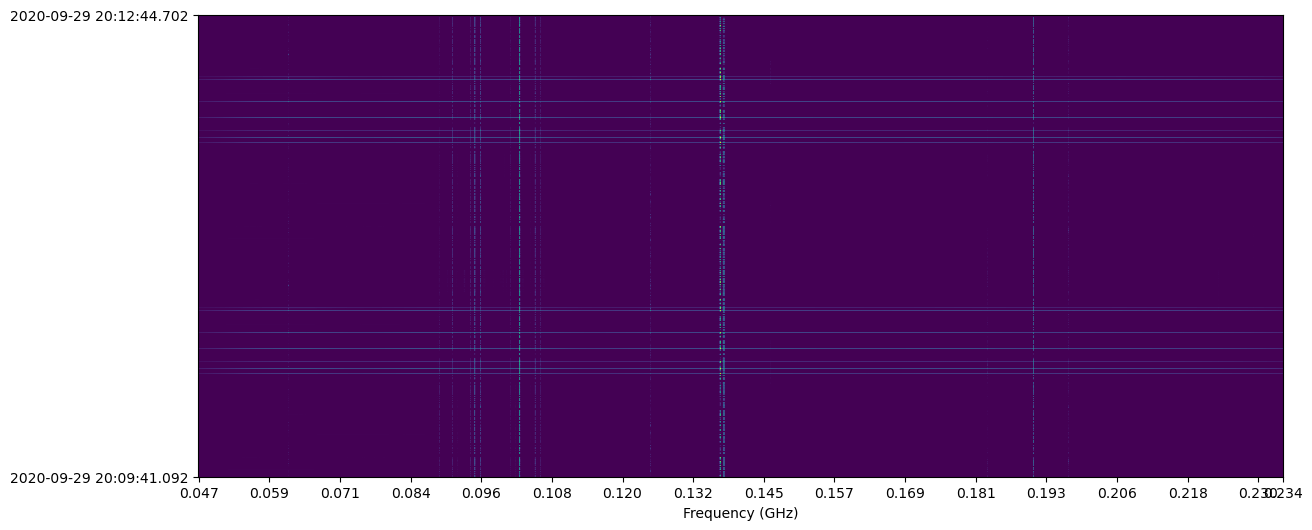

In [5]:
#Waterfall plot
fig, ax = plt.subplots(1, 1)
_ = ax.imshow(np.abs(data_unflagged), interpolation="none", origin="lower", aspect="auto")
_ = ax.set_yticks([0, waterfall_times.size - 1])
_ = ax.set_yticklabels([waterfall_times[0], waterfall_times[-1]])
freq_tick_inds = np.concatenate([np.arange(0, uvd.Nfreqs, 100), [uvd.Nfreqs - 1]])
_ = ax.set_xticks(freq_tick_inds)
_ = ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds] * 1e-9])
_ = ax.set_xlabel("Frequency (GHz)")

plt.show()

In [6]:
#Finding mean value for freq; axis = 0
freq_mean = np.ma.mean(np.abs(data_unflagged), axis = 0)

#Creates 5 sigma threshold
threshold1 = np.mean(freq_mean) + 5 * np.std(freq_mean)

#Freq to delete
die_freqs1 = freq_mean > threshold1

#Filter out freqs
data_copy1 = np.abs(data_unflagged).copy()
good_freq_data1 = data_copy1[:, ~die_freqs1]

In [7]:
#Finding mean value for time; axis = 1
time_mean = np.ma.mean(np.abs(good_freq_data1), axis = 1)

#Creates 5 sigma threshold
threshold2 = np.mean(time_mean) + 5 * np.std(time_mean)

#Times to delete
die_time1 = time_mean > threshold2

#Filter out times
data_copy2 = np.abs(good_freq_data1).copy()
good_data1 = data_copy2[~die_time1, :]

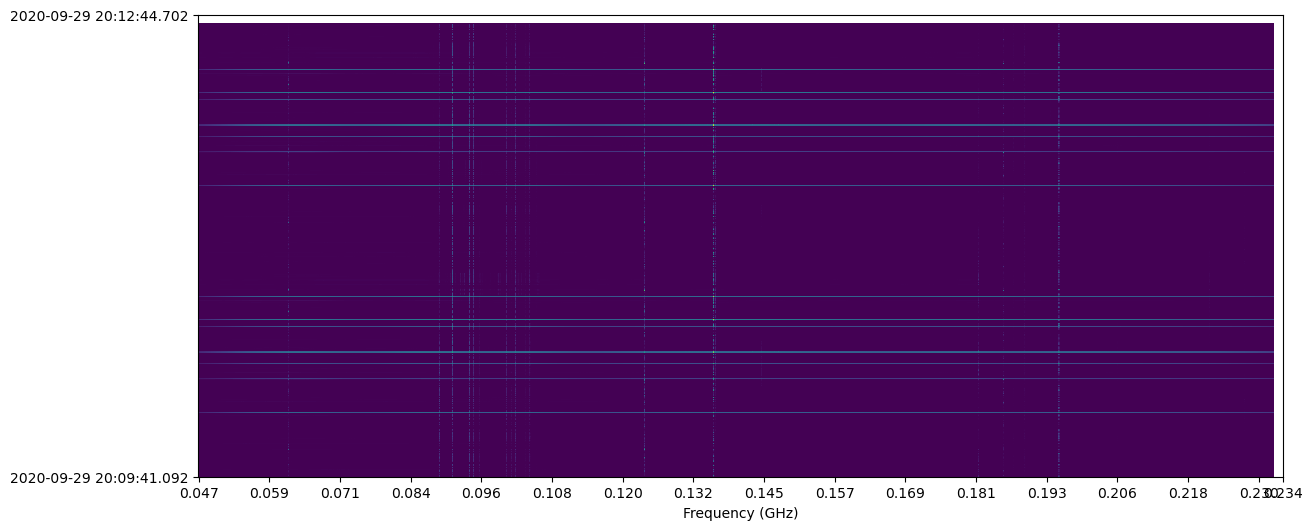

In [8]:
fig, ax = plt.subplots(1, 1)
_ = ax.imshow(np.abs(good_data1), interpolation="none", origin="lower", aspect="auto")
_ = ax.set_yticks([0, waterfall_times.size - 1])
_ = ax.set_yticklabels([waterfall_times[0], waterfall_times[-1]])
freq_tick_inds = np.concatenate([np.arange(0, uvd.Nfreqs, 100), [uvd.Nfreqs - 1]])
_ = ax.set_xticks(freq_tick_inds)
_ = ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds] * 1e-9])
_ = ax.set_xlabel("Frequency (GHz)")

plt.show()

In [9]:
#Finding median value for freq; axis = 0
freq_median = np.ma.median(np.abs(data_unflagged), axis = 0)

#Creates 5 sigma threshold
threshold3 = np.mean(freq_median) + 5 * np.std(freq_median)

#Freq to delete
die_freqs2 = freq_median > threshold3

#Filter out freqs
data_copy3 = np.abs(data_unflagged).copy()
good_freq_data2 = data_copy3[:, ~die_freqs2]

In [10]:
#Finding mean value for time; axis = 1
time_median = np.ma.median(np.abs(good_freq_data2), axis = 1)

#Creates 5 sigma threshold
threshold4 = np.mean(time_median) + 5 * np.std(time_median)

#Times to delete
die_time2 = time_median > threshold4

#Filter out times
data_copy4 = np.abs(good_freq_data2).copy()
good_data2 = data_copy4[~die_time2, :]

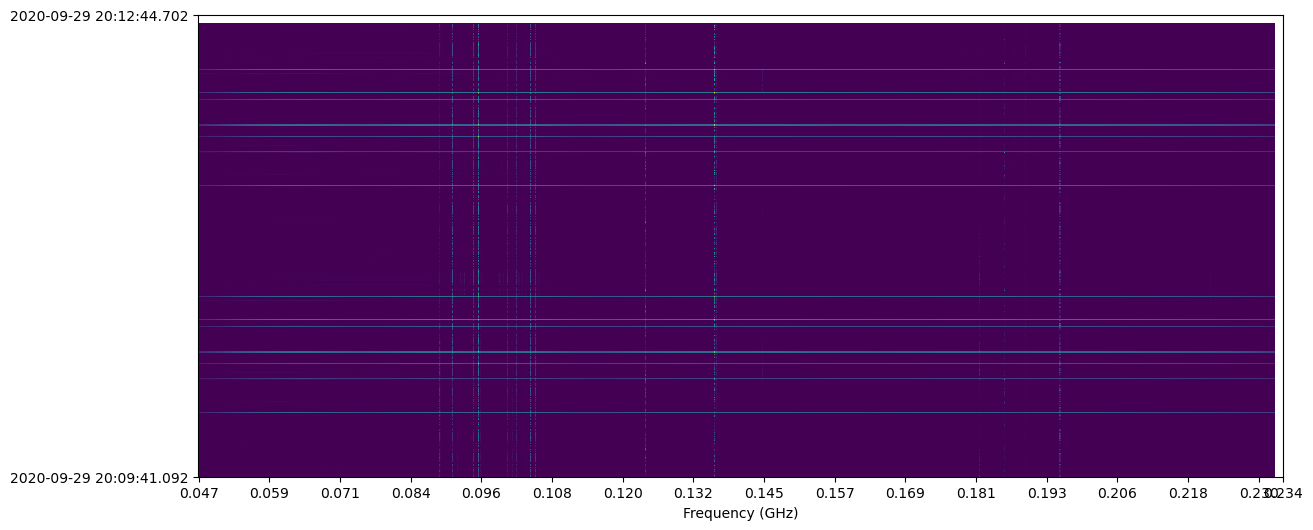

In [11]:
fig, ax = plt.subplots(1, 1)
_ = ax.imshow(np.abs(good_data2), interpolation="none", origin="lower", aspect="auto")
_ = ax.set_yticks([0, waterfall_times.size - 1])
_ = ax.set_yticklabels([waterfall_times[0], waterfall_times[-1]])
freq_tick_inds = np.concatenate([np.arange(0, uvd.Nfreqs, 100), [uvd.Nfreqs - 1]])
_ = ax.set_xticks(freq_tick_inds)
_ = ax.set_xticklabels([f"{val:.3f}" for val in uvd.freq_array[freq_tick_inds] * 1e-9])
_ = ax.set_xlabel("Frequency (GHz)")

plt.show()

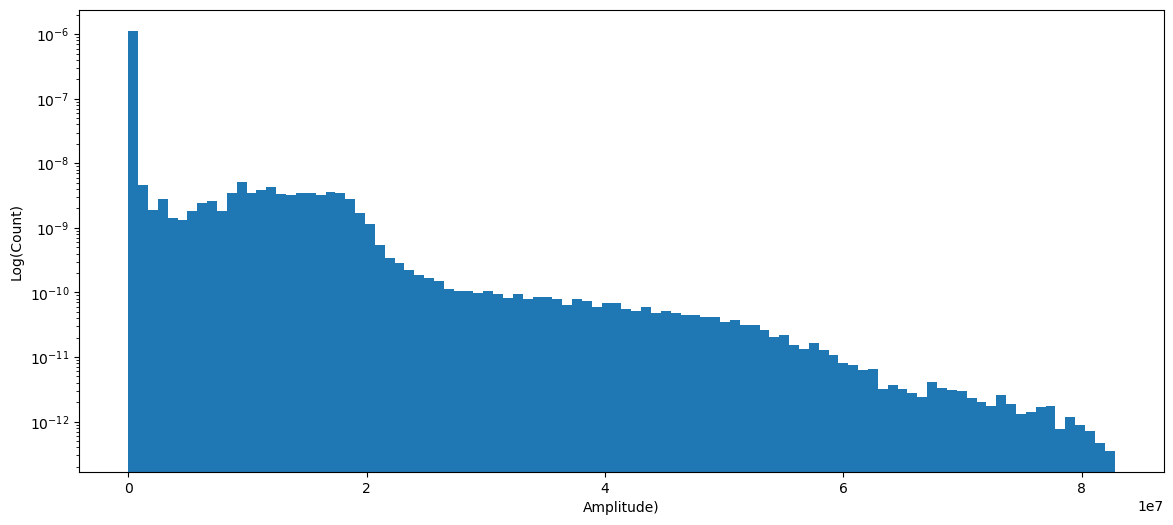

In [12]:
data = np.abs(data_unflagged).compressed()

plt.hist(data, bins=100, density = True)
plt.xlabel("Amplitude)")
plt.ylabel("Log(Count)")

plt.yscale('log')
plt.show()

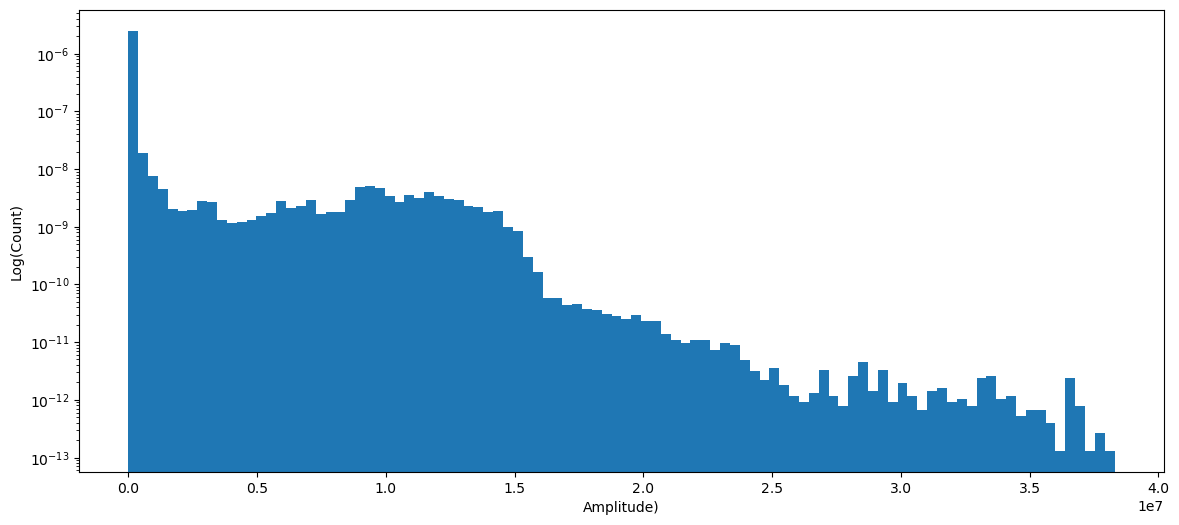

In [13]:
data = np.abs(good_data1).compressed()

plt.hist(data, bins=100, density = True)
plt.xlabel("Amplitude)")
plt.ylabel("Log(Count)")

plt.yscale('log')
plt.show()